# 03 · Interpretabilidad — Detección de fraude (PaySim)

**Objetivo:** entender **qué** aprendió el modelo campeón (XGBoost, notebook 02) y **por qué** decide en casos
concretos, y contrastarlo con los patrones de fraude esperados.

| Alcance | Técnica | Pregunta que responde |
|---|---|---|
| Global | SHAP summary y bar | ¿Qué features empujan el score y en qué dirección? |
| Global | Permutation importance | ¿Cuánto PR-AUC se pierde si una feature deja de tener información? |
| Global | PDP / ICE | ¿Cómo cambia la probabilidad de fraude al variar una feature? |
| Local | SHAP waterfall | ¿Cómo se construye el score de una transacción concreta? |
| Local | LIME | ¿Qué reglas locales explican la decisión, según un modelo lineal en el vecindario? |

Todo se calcula sobre el **test** (steps 313–400), con el modelo ya fijado. Producción no se usa.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.inspection import permutation_importance

from fraud_detection import config
from fraud_detection.interpret import (
    explain_sample,
    lime_explainer,
    lime_predict_fn,
    lime_row,
    load_champion,
    partial_dependence_ice,
    select_local_cases,
    shap_explanation,
    shap_importance,
)
from fraud_detection.plots import COLOR_FRAUD, COLOR_LEGIT, finish, set_style
from fraud_detection.tracking import log_model_run, setup_mlflow

os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"
warnings.filterwarnings("ignore", module="mlflow")
warnings.filterwarnings("ignore", message="IProgress not found")
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 30)

model, meta = load_champion()
FEATURES, THRESHOLD = meta["features"], meta["threshold"]
setup_mlflow(config.MLFLOW_EXPERIMENT_TRAINING)

test = pd.read_parquet(config.TEST_PARQUET, columns=FEATURES + ["step", "type", "isFraud"])
X_test, y_test = test[FEATURES], test["isFraud"].to_numpy()
scores = model.predict_proba(X_test)[:, 1]
figures, tables = {}, {}
print(f"Modelo: {meta['model_name']} v{meta['version']} | threshold {THRESHOLD:.4f} | "
      f"test {len(test):,} filas, {y_test.sum()} fraudes")

/home/r_mejia/Project-MLEngineer3/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo: xgboost v2 | threshold 0.8275 | test 611,113 filas, 956 fraudes


## 1. SHAP global

SHAP descompone cada predicción en aportes aditivos por feature (en log-odds), partiendo del valor base (la
predicción promedio). Para modelos de árboles **TreeSHAP es exacto**, no una aproximación.

Se explica una muestra del test con **todos los fraudes (956) y 5,000 legítimos**; sobre-representar los fraudes
permite ver bien el comportamiento de ambas clases.

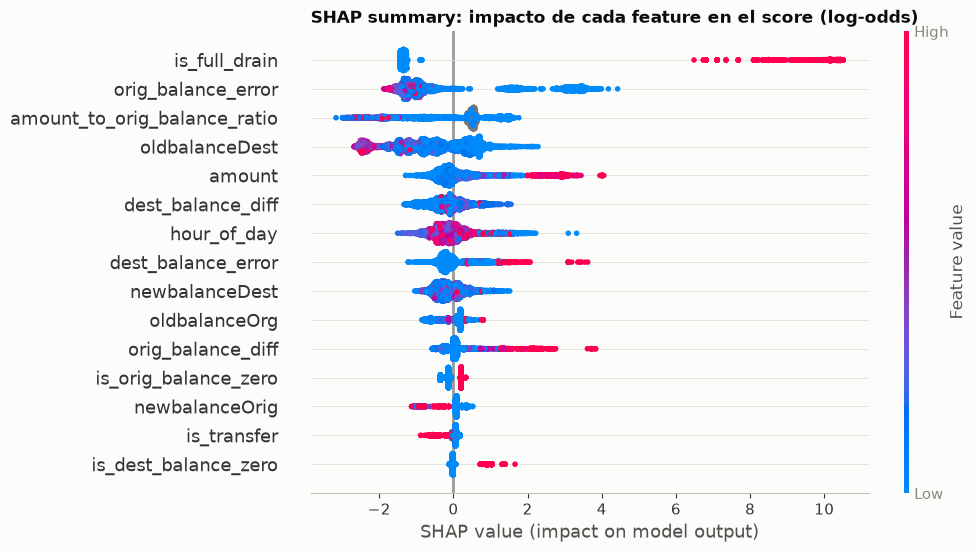

In [2]:
sample = explain_sample(test, n_legit=5_000)
X_exp = sample[FEATURES]
expl = shap_explanation(model, X_exp)
shap_imp = shap_importance(expl)

shap.plots.beeswarm(expl, max_display=15, show=False, plot_size=(9, 6))
plt.title("SHAP summary: impacto de cada feature en el score (log-odds)", loc="left", fontsize=12)
figures["shap_summary"] = plt.gcf()
plt.show()

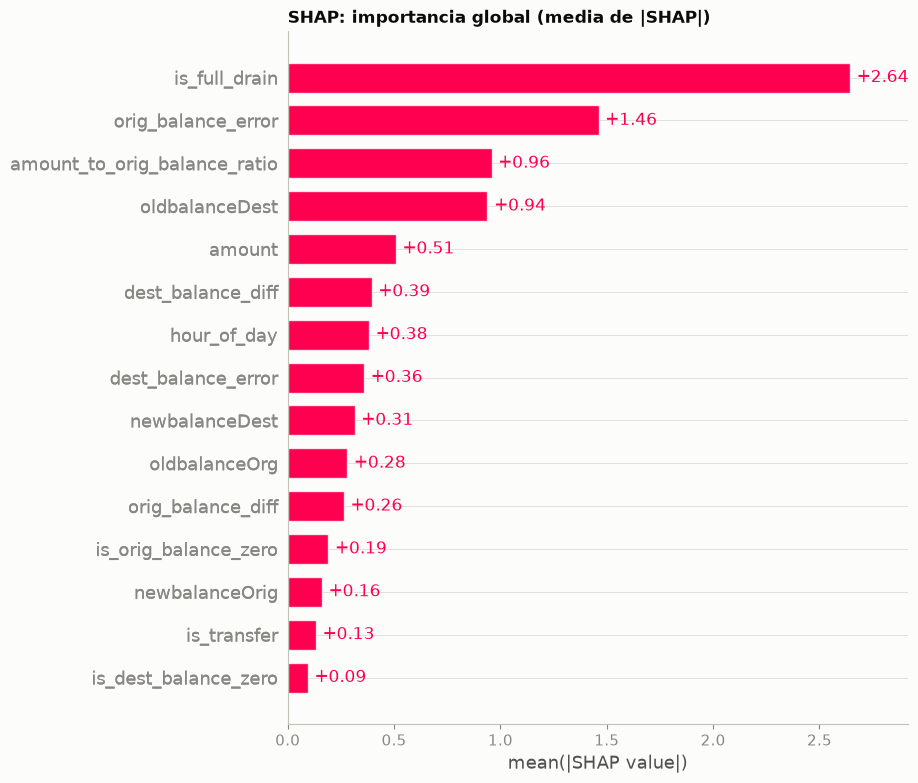

,media |SHAP|
is_full_drain,2.6438
orig_balance_error,1.4613
amount_to_orig_balance_ratio,0.9581
oldbalanceDest,0.9391
amount,0.5084
dest_balance_diff,0.3950
hour_of_day,0.3824
dest_balance_error,0.3591
newbalanceDest,0.3149
oldbalanceOrg,0.2799


In [3]:
shap.plots.bar(expl, max_display=15, show=False)
plt.title("SHAP: importancia global (media de |SHAP|)", loc="left", fontsize=12)
figures["shap_bar"] = plt.gcf()
plt.show()
tables["shap_importance"] = shap_imp.rename("mean_abs_shap").rename_axis("feature").reset_index()
shap_imp.to_frame("media |SHAP|")

**Lectura**
- **`is_full_drain` domina** (media |SHAP| 2.64, casi el doble que la siguiente). Cuando vale 1 suma entre +6 y +10
  log-odds, suficiente por sí sola para llevar el score a ~1.
- **`orig_balance_error`** es la segunda: un error ≈ 0 (el saldo del origen *cuadra*) **sube** el score, y un error
  grande lo baja. Confirma el artefacto visto en el EDA: en PaySim los legítimos casi nunca cuadran y los fraudes sí.
- **`oldbalanceDest`**: un destino con saldo alto **baja** el score; los fraudes van a cuentas destino vacías (mulas).
- **`amount`** alto empuja hacia fraude, coherente con la cola pesada de montos del fraude (tope 10 M).
- `hour_of_day` aporta poco pero en la dirección esperada (madrugada → más riesgo).

## 2. Permutation importance

Se desordena cada feature (5 repeticiones) y se mide **cuánto cae el PR-AUC** en el test. A diferencia de SHAP, mide
la dependencia del **desempeño**, no de la predicción. Muestra: todos los fraudes del test más 50,000 legítimos.

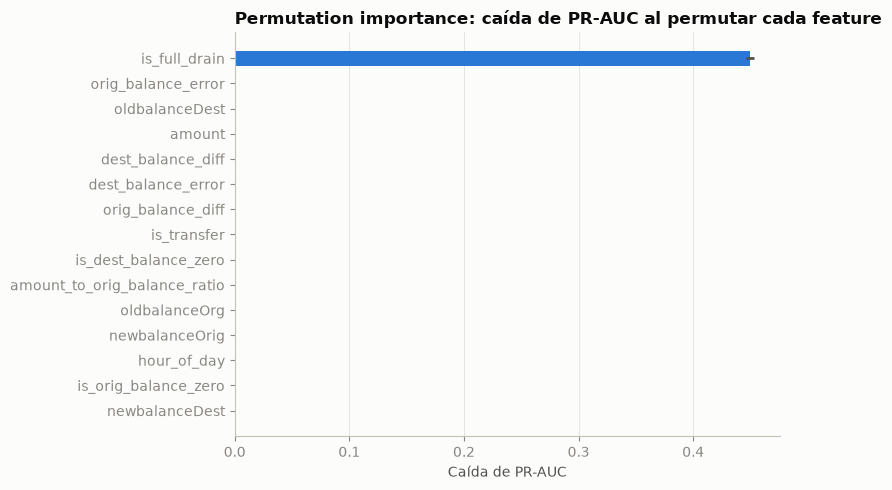

,caida_pr_auc,std,rank_shap,rank_permutation,rank_xgb_gain
is_full_drain,0.4495,0.0036,1,1,1
orig_balance_error,0.0015,0.0000,2,2,4
amount_to_orig_balance_ratio,-0.0000,0.0000,3,10,5
oldbalanceDest,0.0001,0.0001,4,3,13
amount,0.0001,0.0000,5,4,9
dest_balance_diff,0.0000,0.0000,6,5,15
hour_of_day,-0.0000,0.0000,7,13,14
dest_balance_error,0.0000,0.0000,8,6,11
newbalanceDest,-0.0000,0.0000,9,15,12
oldbalanceOrg,-0.0000,0.0000,10,11,10


In [4]:
perm_sample = explain_sample(test, n_legit=50_000)
perm = permutation_importance(
    model, perm_sample[FEATURES], perm_sample["isFraud"].to_numpy(), scoring="average_precision",
    n_repeats=5, random_state=config.SEED, n_jobs=1,
)
perm_imp = pd.DataFrame({"caida_pr_auc": perm.importances_mean, "std": perm.importances_std}, index=FEATURES)
perm_imp = perm_imp.sort_values("caida_pr_auc", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
data = perm_imp.iloc[::-1]
ax.barh(data.index, data["caida_pr_auc"], xerr=data["std"], color=COLOR_LEGIT, height=0.6, ecolor="#52514e")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
finish(ax, "Permutation importance: caída de PR-AUC al permutar cada feature", "Caída de PR-AUC", "")
fig.tight_layout()
figures["permutation_importance"] = fig
plt.show()

native = pd.Series(model.feature_importances_, index=FEATURES)
ranking = pd.DataFrame({
    "rank_shap": shap_imp.rank(ascending=False),
    "rank_permutation": perm_imp["caida_pr_auc"].rank(ascending=False),
    "rank_xgb_gain": native.rank(ascending=False),
}).astype(int).sort_values("rank_shap")
tables["permutation_importance"] = perm_imp.rename_axis("feature").reset_index()
tables["importance_ranking"] = ranking.rename_axis("feature").reset_index()
pd.concat([perm_imp, ranking], axis=1).sort_values("rank_shap")

**Lectura**
- Permutar **`is_full_drain` hace caer el PR-AUC 0.45** puntos. Permutar cualquier otra feature cuesta ≤ 0.0015.
- Que el resto dé ≈ 0 **no** significa que no se usen (SHAP muestra que sí), sino que son **redundantes**: si se
  desordena una, las demás describen la misma relación monto ↔ saldo y el modelo compensa.
  `is_full_drain` es la única que resume en una sola variable "vació la cuenta".
- Los tres rankings (SHAP, permutación, *gain* de XGBoost) coinciden en el primer lugar y difieren después. El *gain*
  nativo está sesgado hacia features usadas en los primeros splits (`is_dest_balance_zero` sale 2.º por gain y 15.º
  por SHAP), por eso no se usa como explicación principal.

## 3. Dependencia parcial (PDP) e ICE

- **PDP (línea gruesa):** probabilidad de fraude promedio al fijar la feature en cada valor, dejando el resto como
  está en los datos.
- **ICE (líneas finas):** la misma curva para transacciones individuales (300 al azar). Si las líneas ICE divergen
  de la PDP, hay **interacciones**: el efecto depende de otras features.

Se grafican las 4 features principales según SHAP, con una grilla entre los percentiles 1 y 99 (los montos en escala
symlog). La muestra es la de SHAP (16 % fraudes), así que el nivel de la PDP refleja esa mezcla.

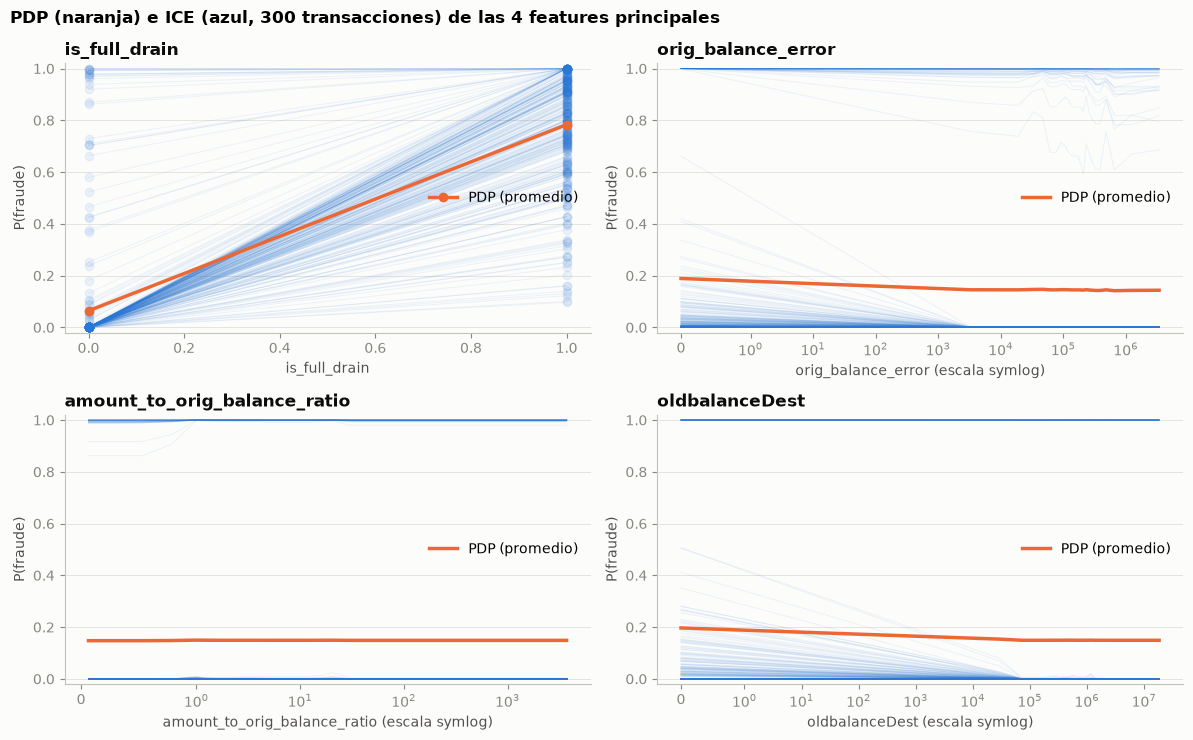

Top 4: ['is_full_drain', 'orig_balance_error', 'amount_to_orig_balance_ratio', 'oldbalanceDest']


In [5]:
top4 = list(shap_imp.index[:4])
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
pdp_rows = []
for ax, feat in zip(axes.ravel(), top4, strict=True):
    grid, ice = partial_dependence_ice(model, X_exp, feat)
    pdp = ice.mean(axis=0)
    style = {"marker": "o"} if len(grid) <= 2 else {}
    for line in ice[:300]:
        ax.plot(grid, line, color=COLOR_LEGIT, alpha=0.08, linewidth=0.7, **style)
    ax.plot(grid, pdp, color=COLOR_FRAUD, linewidth=2.5, label="PDP (promedio)", **style)
    if len(grid) > 2 and grid.max() > 100:
        ax.set_xscale("symlog", linthresh=1)
    ax.set_ylim(-0.02, 1.02)
    ax.legend(loc="center right")
    finish(ax, feat, feat + (" (escala symlog)" if ax.get_xscale() == "symlog" else ""), "P(fraude)")
    pdp_rows += [{"feature": feat, "valor": g, "pdp": p} for g, p in zip(grid, pdp, strict=True)]
fig.suptitle("PDP (naranja) e ICE (azul, 300 transacciones) de las 4 features principales",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
figures["pdp_ice_top4"] = fig
tables["pdp_top4"] = pd.DataFrame(pdp_rows)
plt.show()
print("Top 4:", top4)

**Lectura**
- **`is_full_drain`**: la PDP pasa de ~0.06 a ~0.78. Casi todas las curvas ICE suben, pero con pendientes distintas:
  hay interacciones (la misma marca pesa menos si otras señales contradicen el fraude).
- **`orig_balance_error`**, **`oldbalanceDest`**: la PDP es casi plana porque promedia dos poblaciones. Las curvas ICE
  muestran el efecto real: las transacciones con score intermedio **caen a 0** cuando el error del origen supera
  ~1,000 o cuando el destino tiene más de ~100 K de saldo. Son umbrales de "esto parece legítimo".
- **`amount_to_orig_balance_ratio`**: plano. Su información ya está en `is_full_drain` (ratio = 1).
- Las curvas ICE están casi todas pegadas a 0 o a 1: el modelo está **muy seguro** en casi todos los casos, y eso
  limita a los métodos basados en perturbaciones (ver LIME abajo).

## 4. Explicaciones locales

Casos elegidos sobre el **test completo** con el threshold del campeón:
1. **Fraude detectado típico** (vacía la cuenta; score mediano entre esos casos).
2. **Fraude detectado que la regla `is_full_drain` no ve**: muestra lo que el modelo aporta sobre la regla.
3. **Fraude no detectado (FN)**: el único del test.
4. **Legítimo con el score más alto**: con 0 falsos positivos en test, es el caso más cercano a una falsa alarma.

In [6]:
cases = select_local_cases(y_test, scores, THRESHOLD, test["is_full_drain"].to_numpy())
case_rows = test.iloc[list(cases.values())].copy()
case_rows.insert(0, "caso", list(cases.keys()))
case_rows.insert(1, "score", scores[list(cases.values())])
tables["local_cases"] = case_rows
case_rows.set_index("caso")[["score", "isFraud", "type"] + FEATURES].T

caso,Fraude detectado (típico),Fraude detectado que la regla no ve,Fraude no detectado (FN),Legítimo más sospechoso (casi FP)
score,1.0000,0.9999,0.2574,0.5223
isFraud,1,1,1,0
type,CASH_OUT,TRANSFER,CASH_OUT,TRANSFER
amount,"653,151.5500","10,000,000.0000",0.0000,"1,985,517.2200"
oldbalanceOrg,"653,151.5500","11,975,271.7700",0.0000,0.0000
newbalanceOrig,0.0000,"1,975,271.7700",0.0000,0.0000
oldbalanceDest,"47,452.2500",0.0000,"7,970,766.5700",0.0000
newbalanceDest,"700,603.8100",0.0000,"7,970,766.5700","1,985,517.2200"
orig_balance_diff,"653,151.5625","10,000,000.0000",0.0000,0.0000
orig_balance_error,0.0000,0.0000,0.0000,"1,985,517.2500"


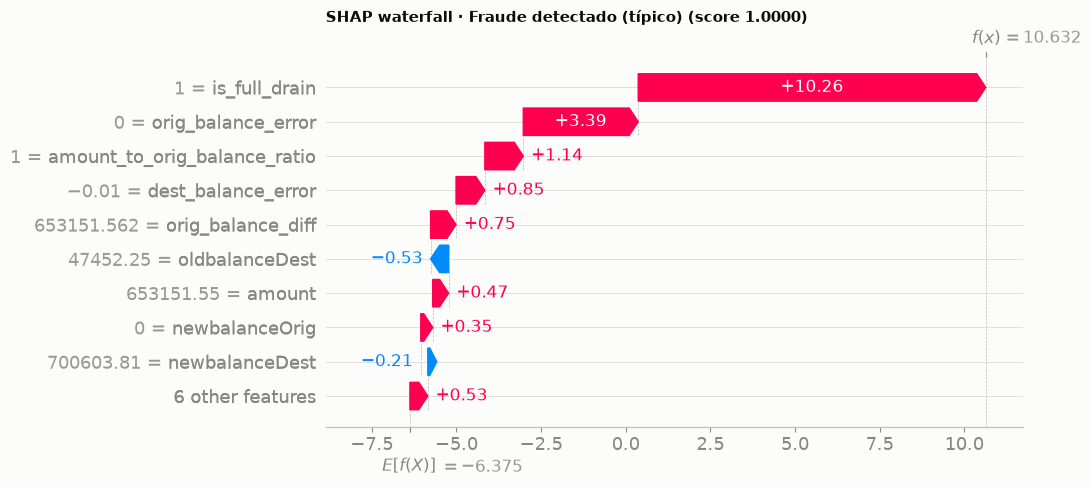

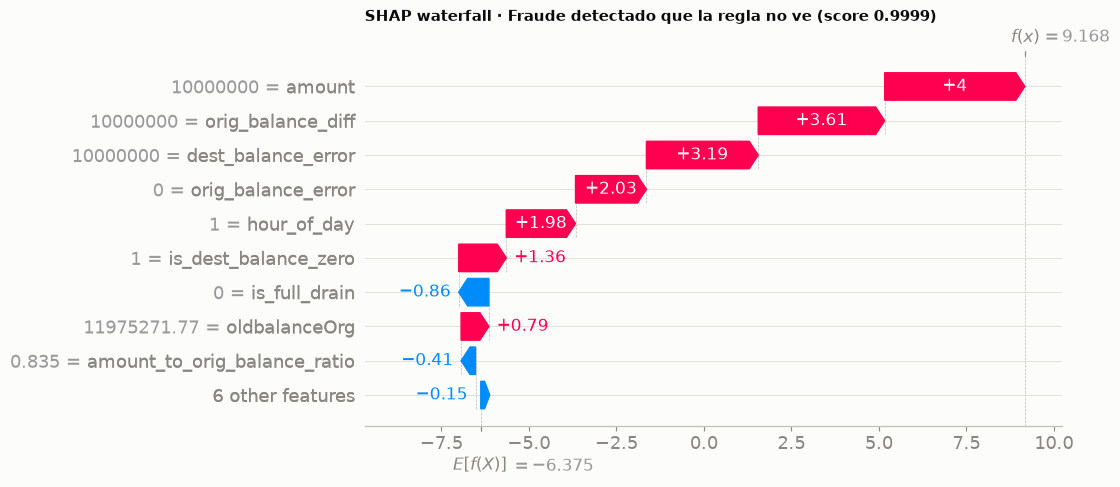

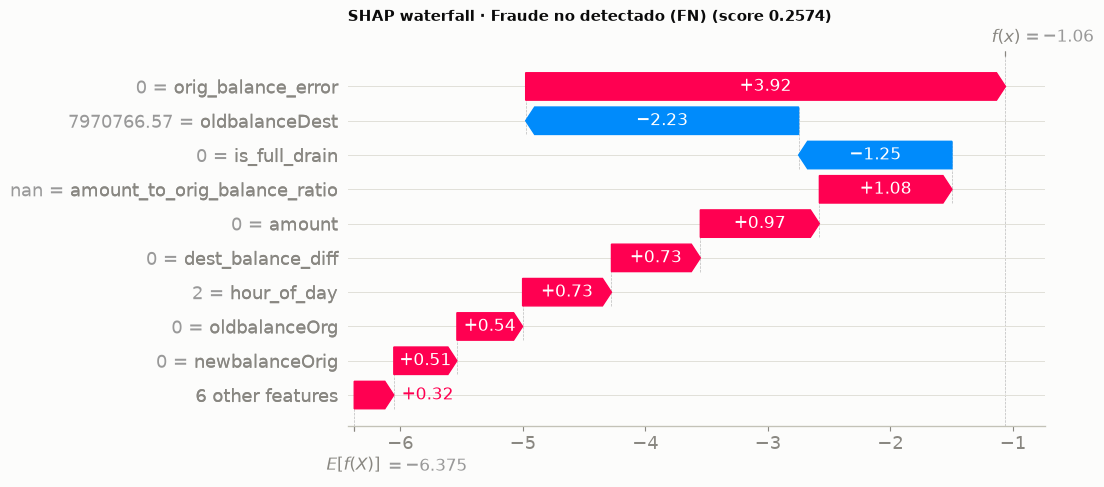

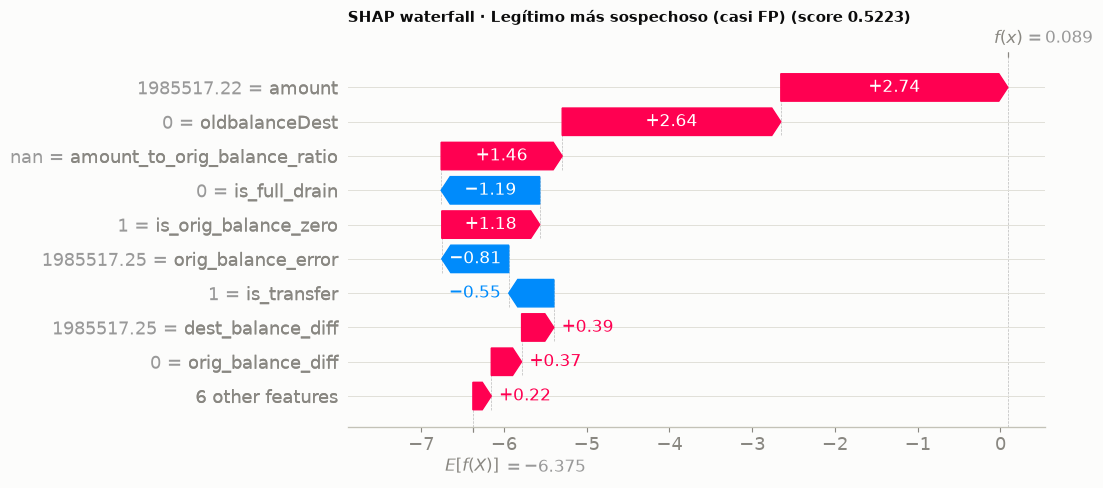

In [7]:
case_expl = shap_explanation(model, X_test.iloc[list(cases.values())])
for k, label in enumerate(cases):
    shap.plots.waterfall(case_expl[k], max_display=10, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 4.8)
    plt.title(f"SHAP waterfall · {label} (score {scores[list(cases.values())[k]]:.4f})", loc="left", fontsize=11)
    figures[f"shap_waterfall_case{k + 1}"] = fig
    plt.show()

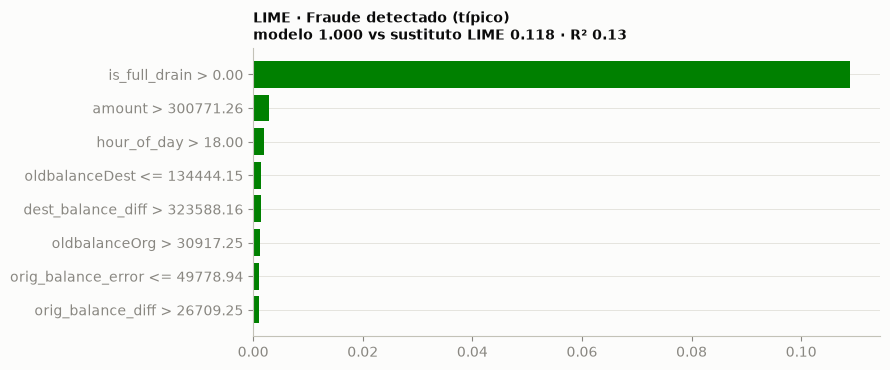

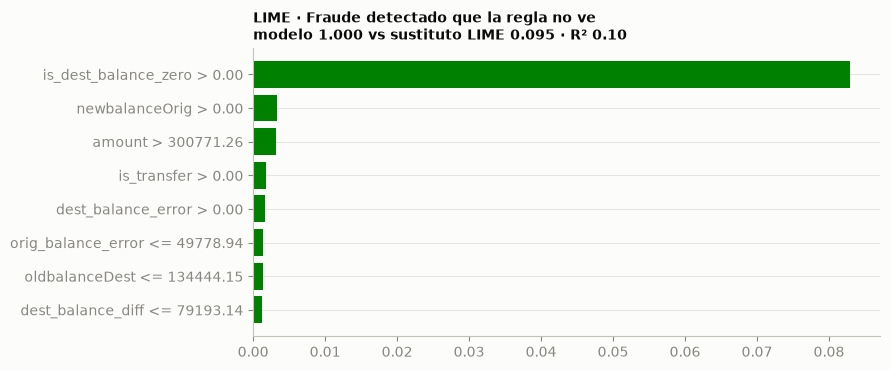

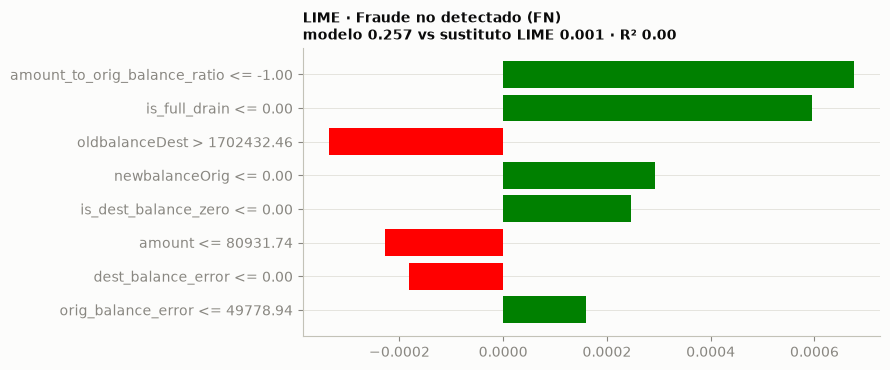

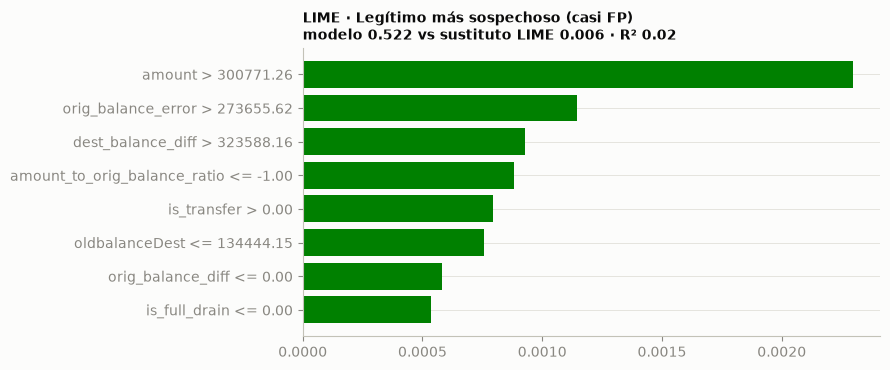

,p_modelo,p_lime,r2_local
caso,,,
Fraude detectado (típico),1.0000,0.1181,0.1287
Fraude detectado que la regla no ve,0.9999,0.0946,0.0996
Fraude no detectado (FN),0.2574,0.0007,0.0041
Legítimo más sospechoso (casi FP),0.5223,0.0060,0.0194


In [8]:
background = pd.read_parquet(config.TRAIN_PARQUET, columns=FEATURES).sample(20_000, random_state=config.SEED)
lime_exp = lime_explainer(background)
predict_fn = lime_predict_fn(model, X_test.dtypes)
lime_rows = []
for k, (label, idx) in enumerate(cases.items()):
    exp = lime_exp.explain_instance(lime_row(X_test.iloc[idx]), predict_fn, num_features=8, num_samples=5_000)
    fig = exp.as_pyplot_figure()
    fig.set_size_inches(9, 3.8)
    model_p = predict_fn(lime_row(X_test.iloc[idx])[None, :])[0, 1]
    plt.title(f"LIME · {label}\nmodelo {model_p:.3f} vs sustituto LIME {exp.local_pred[0]:.3f} · R² {exp.score:.2f}",
              loc="left", fontsize=10)
    plt.tight_layout()
    figures[f"lime_case{k + 1}"] = fig
    plt.show()
    lime_rows += [{"caso": label, "regla_lime": rule, "peso": w, "r2_local": exp.score,
                   "p_modelo": model_p, "p_lime": exp.local_pred[0]} for rule, w in exp.as_list()]
tables["lime_explanations"] = pd.DataFrame(lime_rows)
tables["lime_explanations"].groupby("caso", sort=False)[["p_modelo", "p_lime", "r2_local"]].first()

**Lectura de los casos**
1. **Fraude típico** (CASH_OUT de 653 K que vacía la cuenta): `is_full_drain` aporta +10.3 log-odds y
   `orig_balance_error = 0` otros +3.4. Es el patrón de libro.
2. **Fraude que la regla no ve** (TRANSFER de exactamente **10 M** desde una cuenta con 11.98 M, a un destino vacío):
   no vacía la cuenta porque la simulación topea el monto en 10 M. El modelo lo detecta (0.9999) por el monto tope
   (+4.0), la diferencia de saldo de 10 M (+3.6), el **destino que no registra el dinero** (`dest_balance_error` =
   10 M, +3.2), la hora (1 a. m., +2.0) y `is_dest_balance_zero` (+1.4). Este es el aporte del modelo sobre la regla.
3. **Fraude no detectado** (score 0.257): un CASH_OUT de **monto 0** desde una cuenta sin saldo hacia un destino
   con 7.97 M. El saldo destino alto (−2.2) y la ausencia de vaciado (−1.25) lo hunden. **No movió dinero**, así que
   no hay pérdida: es un registro degenerado de la simulación más que un fraude real perdido.
4. **Legítimo más sospechoso** (score 0.522 < 0.828): TRANSFER de 1.99 M desde una cuenta con saldo 0 hacia un
   destino vacío. El monto alto (+2.7) y el destino vacío (+2.6) lo acercan al fraude. Que el origen no cuadre
   (`orig_balance_error` = 1.99 M, −0.8) y no haya vaciado (−1.2) lo frenan. El threshold robusto deja margen aquí.

**SHAP vs LIME:** el sustituto lineal de LIME tiene **R² entre 0.00 y 0.13** y predice probabilidades muy distintas
a las del modelo (p. ej. 0.001 vs 0.257 en el FN). Con un modelo tan saturado, las perturbaciones aleatorias de LIME
casi siempre caen en zonas de probabilidad ≈ 0, y el modelo lineal local no tiene variación que explicar. Las
direcciones que marca LIME coinciden en general con SHAP (p. ej. `oldbalanceDest` alto en contra del fraude en el
FN), pero **para este modelo la explicación local confiable es SHAP**, que es exacto para árboles.

## 5. Registro en MLflow

Todas las figuras y tablas de este notebook se guardan como artefactos del run `interpretability`, vinculado a la
versión registrada del modelo campeón.

In [9]:
run_id, _ = log_model_run(
    "interpretability",
    params={"model": meta["model_name"], "registered_version": meta["version"], "threshold": THRESHOLD,
            "shap_sample": len(X_exp), "permutation_sample": len(perm_sample)},
    metrics={f"mean_abs_shap__{f}": v for f, v in shap_imp.items()}
    | {f"perm_pr_auc_drop__{f}": v for f, v in perm_imp["caida_pr_auc"].items()},
    tags={"stage": "interpretability", "model": meta["model_name"], "champion_run_id": meta["mlflow_run_id"]},
    figures=figures,
    tables=tables,
)
for f in figures.values():
    plt.close(f)
print(f"Run interpretability: {run_id} ({len(figures)} figuras, {len(tables)} tablas)")

Run interpretability: 2073dcd4e71a4887acd76f9da01d959f (12 figuras, 6 tablas)


## 6. Conclusión de negocio

| Patrón esperado (enunciado) | ¿Lo usa el modelo? | Evidencia |
|---|---|---|
| Vaciado total de la cuenta (`amount ≈ oldbalanceOrg`) | **Sí, es la señal principal** | SHAP #1, permutación −0.45 PR-AUC, PDP 0.06 → 0.78 |
| Saldos que no cuadran con el monto | **Sí, pero al revés de lo intuitivo** | En PaySim el origen de los fraudes *sí* cuadra; un error grande indica legítimo (ICE cae a 0) |
| Transferencias grandes a cuentas vacías | **Sí** | `oldbalanceDest` bajo y `is_dest_balance_zero` suben el score; caso 2 |
| Transferencias grandes a merchants | **No aplica** | Los merchants solo reciben PAYMENT, donde no hay fraude |
| Horario | Sí, en menor medida | `hour_of_day` de madrugada suma (+2.0 en el caso 2) |

- El modelo aprendió **la lógica del agente fraudulento de PaySim**: tomar una cuenta, vaciarla (o mover el tope de
  10 M) hacia una cuenta mula vacía, y retirar. Es coherente con la definición del dataset.
- **Riesgo:** la dependencia de `is_full_drain` hace al modelo frágil si el fraude cambia de táctica (por ejemplo,
  vaciados parciales). Es justo lo que debe vigilar el monitoreo de la Fase 4: la distribución de `is_full_drain`
  y de `orig_balance_error`, y el recall por periodo.
- La única transacción fraudulenta no detectada en test no movió dinero; el costo real del error es 0.